<a href="https://colab.research.google.com/github/bhanukiran29/BISLAB_1WN24CS150/blob/main/BIS_LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       GREY WOLF OPTIMIZATION - TRAFFIC SIGNAL CONTROL
Roads: 4 | Wolves: 20 | Iterations: 100
Signal Cycle: 120 seconds
--------------------------------------------------------------------
ITERATION      BEST WAIT TIME      IMPROVEMENT
--------------------------------------------------------------------
10             1297.25             4.17%
20             1294.95             4.34%
30             1294.12             4.40%
40             1294.12             4.40%
50             1294.12             4.40%
60             1294.03             4.41%
70             1293.94             4.42%
80             1293.79             4.43%
90             1293.74             4.43%
100            1293.62             4.44%

                 OPTIMIZATION RESULTS
ROAD        BEFORE (SEC)      AFTER (SEC)       
--------------------------------------------------------------------
North       25.00             28.56             
South       25.00             16.01             
East        25.00            

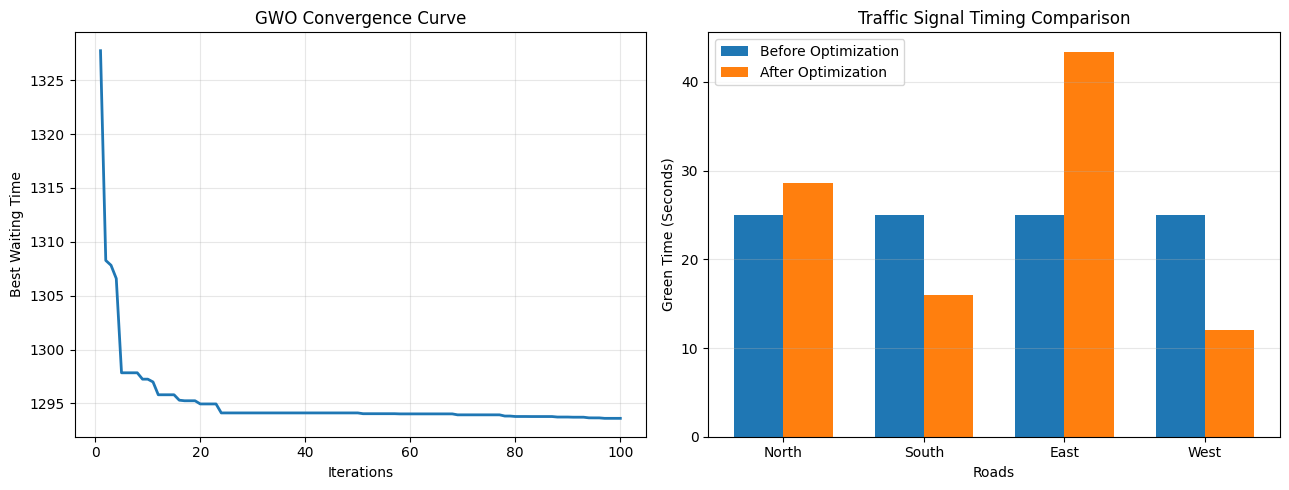

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================
# TRAFFIC SIGNAL OPTIMIZATION USING GWO
# ============================================

np.random.seed(42)

# Traffic simulation parameters
roads = ["North", "South", "East", "West"]
traffic = np.array([5, 4, 6, 3])  # Vehicles per minute

CYCLE_TIME = 120
TOTAL_GREEN = 100
MIN_GREEN = 10
SATURATION_FLOW = 0.5  # Vehicles served per second

# GWO parameters
WOLVES = 20
ITERATIONS = 100
DIM = 4

# ============================================
# FITNESS FUNCTION
# ============================================

def decode_timing(position):
    """Convert wolf position into valid signal timings."""
    position = np.maximum(position, 0)

    if np.sum(position) == 0:
        position = np.ones(DIM)

    remaining = TOTAL_GREEN - DIM * MIN_GREEN

    green = MIN_GREEN + (
        position / np.sum(position)
    ) * remaining

    return green


def calculate_waiting_time(green):
    """Estimate total vehicle waiting time per cycle."""

    total_wait = 0

    for i in range(DIM):
        arrivals = traffic[i] * CYCLE_TIME / 60
        capacity = green[i] * SATURATION_FLOW
        red_time = CYCLE_TIME - green[i]

        # Estimated uniform signal delay
        delay = arrivals * (red_time ** 2) / (2 * CYCLE_TIME)

        # Penalty for vehicles not served during the cycle
        queue = max(0, arrivals - capacity)
        queue_penalty = queue * CYCLE_TIME * 2

        total_wait += delay + queue_penalty

    return total_wait


# ============================================
# INITIALIZE GREY WOLVES
# ============================================

wolves = np.random.uniform(0.1, 1.0, (WOLVES, DIM))

alpha_pos = None
beta_pos = None
delta_pos = None

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

convergence = []

baseline_green = np.full(DIM, TOTAL_GREEN / DIM)
baseline_wait = calculate_waiting_time(baseline_green)

# ============================================
# GREY WOLF OPTIMIZATION
# ============================================

print("=" * 68)
print("       GREY WOLF OPTIMIZATION - TRAFFIC SIGNAL CONTROL")
print("=" * 68)

print(f"Roads: {DIM} | Wolves: {WOLVES} | Iterations: {ITERATIONS}")
print(f"Signal Cycle: {CYCLE_TIME} seconds")
print("-" * 68)

print(f"{'ITERATION':<15}{'BEST WAIT TIME':<20}{'IMPROVEMENT'}")
print("-" * 68)

for iteration in range(ITERATIONS):

    # Evaluate fitness of every wolf
    for i in range(WOLVES):

        green = decode_timing(wolves[i])
        fitness = calculate_waiting_time(green)

        if fitness < alpha_score:
            delta_score = beta_score
            delta_pos = beta_pos.copy() if beta_pos is not None else None

            beta_score = alpha_score
            beta_pos = alpha_pos.copy() if alpha_pos is not None else None

            alpha_score = fitness
            alpha_pos = wolves[i].copy()

        elif fitness < beta_score:
            delta_score = beta_score
            delta_pos = beta_pos.copy() if beta_pos is not None else None

            beta_score = fitness
            beta_pos = wolves[i].copy()

        elif fitness < delta_score:
            delta_score = fitness
            delta_pos = wolves[i].copy()

    # Decrease a from 2 to 0
    a = 2 - 2 * iteration / ITERATIONS

    # Update positions of wolves
    for i in range(WOLVES):

        r1, r2 = np.random.rand(DIM), np.random.rand(DIM)
        A1 = 2 * a * r1 - a
        C1 = 2 * r2
        D_alpha = abs(C1 * alpha_pos - wolves[i])
        X1 = alpha_pos - A1 * D_alpha

        r1, r2 = np.random.rand(DIM), np.random.rand(DIM)
        A2 = 2 * a * r1 - a
        C2 = 2 * r2
        D_beta = abs(C2 * beta_pos - wolves[i])
        X2 = beta_pos - A2 * D_beta

        r1, r2 = np.random.rand(DIM), np.random.rand(DIM)
        A3 = 2 * a * r1 - a
        C3 = 2 * r2
        D_delta = abs(C3 * delta_pos - wolves[i])
        X3 = delta_pos - A3 * D_delta

        wolves[i] = (X1 + X2 + X3) / 3

    # Keep wolves within search boundaries
    wolves = np.clip(wolves, 0.001, 1.0)

    convergence.append(alpha_score)

    # Display every 10 iterations
    if (iteration + 1) % 10 == 0:
        improvement = (
            (baseline_wait - alpha_score) / baseline_wait
        ) * 100

        print(
            f"{iteration + 1:<15}"
            f"{alpha_score:<20.2f}"
            f"{improvement:.2f}%"
        )

# ============================================
# FINAL RESULTS
# ============================================

best_green = decode_timing(alpha_pos)
optimized_wait = calculate_waiting_time(best_green)

improvement = (
    (baseline_wait - optimized_wait) / baseline_wait
) * 100

print("\n" + "=" * 68)
print("                 OPTIMIZATION RESULTS")
print("=" * 68)

print(f"{'ROAD':<12}{'BEFORE (SEC)':<18}{'AFTER (SEC)':<18}")
print("-" * 68)

for i in range(DIM):
    print(
        f"{roads[i]:<12}"
        f"{baseline_green[i]:<18.2f}"
        f"{best_green[i]:<18.2f}"
    )

print("-" * 68)
print(f"Initial Waiting Time   : {baseline_wait:.2f} vehicle-seconds")
print(f"Optimized Waiting Time : {optimized_wait:.2f} vehicle-seconds")
print(f"Waiting Time Reduction : {improvement:.2f}%")
print("=" * 68)

# ============================================
# VISUALIZATION
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Convergence graph
axes[0].plot(
    range(1, ITERATIONS + 1),
    convergence,
    linewidth=2
)

axes[0].set_title("GWO Convergence Curve")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel("Best Waiting Time")
axes[0].grid(True, alpha=0.3)

# Traffic timing comparison
x = np.arange(DIM)
width = 0.35

axes[1].bar(
    x - width / 2,
    baseline_green,
    width,
    label="Before Optimization"
)

axes[1].bar(
    x + width / 2,
    best_green,
    width,
    label="After Optimization"
)

axes[1].set_title("Traffic Signal Timing Comparison")
axes[1].set_xlabel("Roads")
axes[1].set_ylabel("Green Time (Seconds)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(roads)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
